# CIR Model to simulate Interest Rate Changes and Liability Hedging
### Implementing the Cox Ingersoll Ross Model for interest rates

We saw in the previous lab that when you look at your financial condition in terms of funding ratio, rather than asset value, even cash can be a risky asset.

We're going to simulate changes in interest rates using the Cox-Ingersoll-Ross model, usually just called the CIR model. It is very similar to what we have already done for generating random stock prices. Instead of a Geometric Brownian Motion, the mean reversion model features parameters to control the speed of mean reversion as well as the long term average rate.

$$ dr_{t}=a(b-r_{t})\,dt+\sigma {\sqrt  {r_{t}}}\,dW_{t} $$

where $a$ is the speed of mean reversion and $b$ is the long term mean rate and $\sigma$ is the volatility parameter.

This can be read as describing the change in interest at any point of time as a multiple of the distance of the current rate from it's long term mean plus a random value that depends on the volatility parameter.

Thus, we can start at some rate $r_0$ and generate a sequence of rates over time using the change in rate defined by the stochastic differential equation above. If we eliminate the ${\sqrt  {r_{t}}}$ term we get the simpler Vasicek model, but the CIR model eliminates the possibility of negative interest rates by shutting down the volatility term as interest rates approach zero. 

### Short Rate vs Annualized Rate

One final piece of math we'll need is that the interest rate being described here is the "instantaneous" or "short rate" ... we will often want to think about interest rates as annualized rates, which means that the instantaneous rate needs to be compounded into an annual rate as follows:

$$ 1 + r_{annual} = e^{r_{inst}} $$


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import edhec_risk_kit as erk

import yfinance as yf

%load_ext autoreload
%autoreload 2

In [2]:
def inst_to_ann(r):
    """
    Converts the short rate to an annualized rate
    """
    return np.expm1(r)

def ann_to_inst(r):
    """
    Convert annualized rate to a short rate 
    """
    return np.log1p(r)

### CIR Model : $$ dr_{t}=a(b-r_{t})\,dt+\sigma {\sqrt  {r_{t}}}\,dW_{t} $$

In [3]:
def cir(n_years=10, n_scenarios=1, a=0.05, b=0.03, sigma=0.05, steps_per_year=12, r_0=None):
    """
    Implementation of the CIR model for Interest Rates
    """
    if r_0 is None : r_0 = b
    r_0 = ann_to_inst(r_0) #Convert into a short rate
    dt = 1/steps_per_year
    
    n_rows = int(n_years*steps_per_year)+1
    shock = np.random.normal(0, scale=np.sqrt(dt), size=(n_rows, n_scenarios)) # n_columns = n_scenarios !
    rates = np.empty_like(shock)
    rates[0] = r_0

    for step in range(1, n_rows):
        r_t = rates[step-1]
        d_r_t = a*(b-r_t)*dt + sigma*np.sqrt(r_t)*shock[step]
        rates[step] = abs(r_t + d_r_t) 

    return pd.DataFrame(data=inst_to_ann(rates), index=range(n_rows))

<Axes: title={'center': "Scénarios d'implémentation du modèle CIR"}>

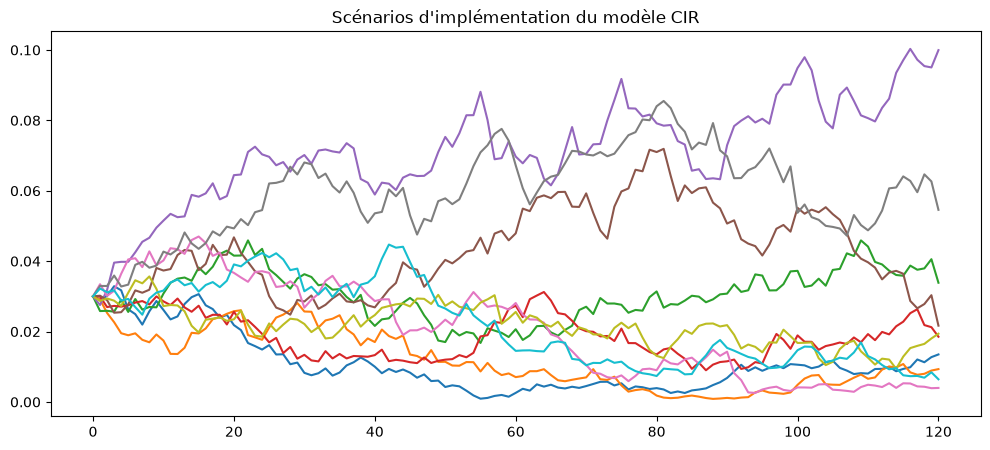

In [4]:
cir(n_scenarios=10, sigma=0.05).plot(figsize=(12,5), legend=False, title="Scénarios d'implémentation du modèle CIR")

# Partie 2 — Du modèle CIR au pricing de dérivés de taux

Jusqu'ici, le modèle CIR m'a servi à **générer des scénarios** de taux d'intérêt. La question devient maintenant : **combien vaut aujourd'hui un produit dont les flux dépendent de ces taux futurs ?**

La démarche suit une progression du plus simple au plus structuré :
| Étape | Produit | Ce que l'on apprend |
|---|---|---|
| 1 | Principe du pricing risque-neutre | Pourquoi un prix est une espérance actualisée |
| 2 | Simulateur adapté au pricing | Ce qu'il faut changer dans le `cir` précédent |
| 3 | Zéro-coupon | La brique d'actualisation, vérifiée contre une formule exacte |
| 4 | Taux forwards | Les taux futurs « implicites » dans la courbe |
| 5 | Swap de taux | Un premier dérivé, linéaire |
| 6 | Caplet et cap | L'optionalité : se protéger contre la hausse des taux |
| 7 | Floor et parité cap–floor | Un test de cohérence indépendant du modèle |
| 8 | Collar de taux | Un produit structuré simple pour un emprunteur |

In [5]:
from matplotlib.ticker import PercentFormatter
from scipy.optimize import brentq

## 2.1 Le principe du pricing risque-neutre

Un dérivé de taux verse un flux futur $\text{Payoff}_T$ qui dépend des taux. Son prix aujourd'hui est :

$$ V_0 = \mathbb{E}^{\mathbb{Q}}\left[ e^{-\int_0^T r_s\,ds} \times \text{Payoff}_T \right] $$

Deux idées dans cette formule :

- **On actualise avec le taux court simulé**, scénario par scénario. Le facteur $e^{-\int_0^T r_s\,ds}$ est donc lui-même aléatoire : si les taux montent dans un scénario, l'argent futur y vaut moins aujourd'hui.
- **L'espérance est prise sous la probabilité risque-neutre $\mathbb{Q}$**, pas sous la probabilité « réelle » $\mathbb{P}$. Sous $\mathbb{Q}$, tout actif rapporte en moyenne le taux sans risque : les primes de risque sont absorbées dans les paramètres du modèle. C'est ce qui garantit des prix **sans opportunité d'arbitrage**, cohérents entre eux.

**Exemple simple.** Si le taux restait constant à 3 %, un flux certain de 100 € dans un an vaudrait $100 \times e^{-0{,}03} = 97{,}04$ €. Avec des taux aléatoires, on fait ce calcul dans chaque scénario, puis on fait la moyenne.

En pratique, cette espérance se calcule par **Monte-Carlo** : simuler beaucoup de trajectoires de $r_t$ sous $\mathbb{Q}$, calculer le flux actualisé dans chacune, puis moyenner.

> **Important :** les paramètres $a$, $b$, $\sigma$ utilisés ci-dessous sont des **paramètres sous $\mathbb{Q}$, choisis à titre illustratif**. Dans une banque, on les **calibrerait** pour que le modèle retrouve les prix observés sur le marché (courbe des taux, volatilités de caps).

## 2.2 Pricing risque-neutre

Un dérivé de taux verse un flux futur $\text{Payoff}_T$ qui dépend des taux. Son prix aujourd'hui est :

$$ V_0 = \mathbb{E}^{\mathbb{Q}}\left[ e^{-\int_0^T r_s\,ds} \times \text{Payoff}_T \right] $$

Deux idées à rappeler :

- **On actualise avec le taux court simulé** scénario par scénario. Le facteur $e^{-\int_0^T r_s\,ds}$ est donc lui-même aléatoire : si les taux montent dans un scénario, l'argent futur y vaut moins aujourd'hui.
- **L'espérance est prise sous la probabilité risque-neutre $\mathbb{Q}$** et non pas sous la probabilité « réelle » $\mathbb{P}$. Sous $\mathbb{Q}$, tout actif rapporte en moyenne le taux sans risque. Cela est une conséquence directe du **principe d'absence d'opportunité d'arbitrage**



> **Détail important :** les paramètres $a$, $b$, $\sigma$ utilisés ci-dessous sont des **paramètres sous $\mathbb{Q}$ que j'ai choisi à titre illustratif**. Afin que le modèle permette le pricing de réels produits , on les **calibrerait** pour retrouver les prix observés sur le marché (courbe des taux, volatilités de caps).

In [2]:
# Paramètres du modèle CIR sous la probabilité risque-neutre Q (valeurs illustratives)
a = 0.3        # vitesse de retour à la moyenne
b = 0.04       # niveau de long terme du taux court (4 %)
sigma = 0.08   # volatilité
r_0 = 0.02     # taux court aujourd'hui (2 %)

# Paramètres numériques
steps_per_year = 52    # pas hebdomadaire
n_scenarios = 50000
seed = 42

# Caractéristiques des produits étudiés
N = 1_000_000    # nominal : 1 M€
delta = 0.25     # paiements trimestriels
maturity = 5     # 5 ans


In [7]:
def cir_short_rates(n_years=5, n_scenarios=1000, a=a, b=b, sigma=sigma, r_0=r_0,
                    steps_per_year=steps_per_year, seed=None):
    """
    Simule le taux court instantané du modèle CIR (sans conversion en taux annuel).
    Lignes = dates en années, colonnes = scénarios.
    """
    if seed is not None:
        np.random.seed(seed)
    dt = 1/steps_per_year
    n_rows = int(round(n_years*steps_per_year)) + 1

    shock = np.random.normal(0, scale=np.sqrt(dt), size=(n_rows, n_scenarios))
    rates = np.empty_like(shock)
    rates[0] = r_0

    for step in range(1, n_rows):
        r_t = rates[step-1]
        d_r_t = a*(b-r_t)*dt + sigma*np.sqrt(r_t)*shock[step]
        rates[step] = abs(r_t + d_r_t)

    return pd.DataFrame(data=rates, index=np.arange(n_rows)*dt)


**Premier contrôle => la moyenne des scénarios.** Dans le modèle CIR, l'espérance du taux court est connue exactement :

$$ \mathbb{E}[r_t] = b + (r_0 - b)\,e^{-a t} $$

Le taux part de $r_0$ et se rapproche de $b$ à une vitesse fixée par $a$ (accélération du retour vers la moyenne). Avec $a = 0{,}3$, l'écart initial est divisé par deux en $\ln 2 / 0{,}3 \approx 2{,}3$ ans. La moyenne des simulations devra suivre cette courbe.

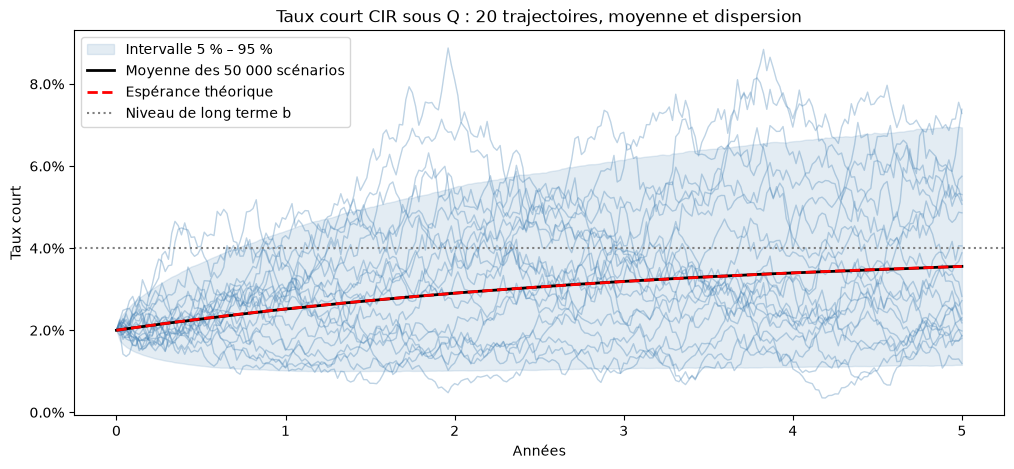

In [8]:
rates = cir_short_rates(n_years=maturity, n_scenarios=n_scenarios, seed=seed)

t = rates.index
expected_rate = b + (r_0 - b)*np.exp(-a*t)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(t, rates.iloc[:, :20], color="steelblue", alpha=0.35, lw=1)
ax.fill_between(t, rates.quantile(0.05, axis=1), rates.quantile(0.95, axis=1),
                color="steelblue", alpha=0.15, label="Intervalle 5 % – 95 %")
ax.plot(t, rates.mean(axis=1), color="black", lw=2, label="Moyenne des 50 000 scénarios")
ax.plot(t, expected_rate, color="red", ls="--", lw=2, label="Espérance théorique")
ax.axhline(b, color="grey", ls=":", label="Niveau de long terme b")

ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.set_title("Taux court CIR sous Q : 20 trajectoires, moyenne et dispersion")
ax.set_xlabel("Années")
ax.set_ylabel("Taux court")
ax.legend(loc="upper left")
plt.show()

**Analyse du résulta:** La moyenne simulée (en noir) se superpose à l'espérance théorique (en rouge) : le simulateur reproduit donc bien le retour à la moyenne. L'éventail des scénarios s'élargit avec le temps, mais reste borné par le bas car le terme $\sigma\sqrt{r_t}$ réduit la volatilité quand le taux se rapproche de zéro.

## 2.3 Le socle => prix d'un zéro-coupon

Un **zéro-coupon** de maturité $T$ verse 1 € en $T$. Tout flux futur certain se valorise donc comme un multiple de zéro-coupon.

### Prix par Monte-Carlo

Dans chaque scénario, le **facteur d'actualisation** est :

$$ D(0,T) = e^{-\int_0^T r_s\,ds} \qquad \text{avec} \qquad \int_0^T r_s\,ds \approx \sum_k r_{t_k}\,\Delta t $$

On additionne les taux des pas précédents et on les multiplie par la durée d'un pas. Le prix du zéro-coupon est la moyenne de ces facteurs :

$$ P(0,T) = \mathbb{E}^{\mathbb{Q}}\left[ D(0,T) \right] $$

### Prix exact

Le modèle CIR a l'avantage de fournir une **formule fermée** pour ce prix :

$$ P(t,T) = A(\tau)\,e^{-B(\tau)\,r_t}, \qquad \tau = T - t,\qquad h = \sqrt{a^2 + 2\sigma^2} $$

$$ A(\tau)=\left(\frac{2h\,e^{(a+h)\tau/2}}{2h+(a+h)(e^{h\tau}-1)}\right)^{2ab/\sigma^2} \qquad B(\tau)=\frac{2(e^{h\tau}-1)}{2h+(a+h)(e^{h\tau}-1)} $$

Cette formule a deux usages : d'abord, cela nous permet de **vérifier** le Monte-Carlo et surtout donner, **à l'intérieur d'une simulation**, le prix en $T$ d'un zéro-coupon à partir du seul taux $r_T$, ce qui sera essentiel pour les caps.

**Exemple :** si $P(0,5) = 0{,}86$, recevoir 100 € dans 5 ans vaut 86 € aujourd'hui. Le **taux zéro-coupon** associé est $R(0,T) = -\ln P(0,T) / T \approx 3{,}0\,\%$ par an.

In [9]:
def discount_factors(rates, steps_per_year=steps_per_year):
    """
    Facteur d'actualisation D(0,t) = exp(-intégrale du taux court) pour chaque date et chaque scénario
    """
    dt = 1/steps_per_year
    integral = (rates*dt).cumsum().shift(1).fillna(0)   # somme des taux des pas précédents
    return np.exp(-integral)


def zcb_price(tau, r, a=a, b=b, sigma=sigma):
    """
    Prix exact CIR d'un zéro-coupon de durée résiduelle tau, quand le taux court vaut r
    """
    h = np.sqrt(a**2 + 2*sigma**2)
    A = ((2*h*np.exp((a+h)*tau/2)) / (2*h + (a+h)*(np.exp(h*tau)-1)))**(2*a*b/sigma**2)
    B = (2*(np.exp(h*tau)-1)) / (2*h + (a+h)*(np.exp(h*tau)-1))
    return A*np.exp(-B*r)

NB : Le `.shift(1)` traduit le fait que l'actualisation entre $t_k$ et $t_{k+1}$ utilise le taux connu en $t_k$ ; à la date 0, l'intégrale vaut donc 0 et $D(0,0)=1$.

In [10]:
discounts = discount_factors(rates)

comparison = pd.DataFrame(index=[1, 2, 3, 4, 5])
for T in comparison.index:
    D_T = discounts.loc[T]
    comparison.loc[T, "Monte-Carlo"] = D_T.mean()
    comparison.loc[T, "Formule exacte"] = zcb_price(T, r_0)
    comparison.loc[T, "Erreur standard MC"] = D_T.std() / np.sqrt(n_scenarios)

comparison["Écart (pb de prix)"] = (comparison["Monte-Carlo"] - comparison["Formule exacte"])*10000
comparison.index.name = "Maturité (ans)"
comparison.round(5)

,Monte-Carlo,Formule exacte,Erreur standard MC,Écart (pb de prix)
Maturité (ans),,,,
1,0.97763,0.97755,0.00003,0.81242
2,0.95156,0.95143,0.00007,1.33093
3,0.92320,0.92306,0.00011,1.45700
4,0.89361,0.89347,0.00015,1.44756
5,0.86356,0.86338,0.00019,1.76974


**Interprétation :** Les deux prix concordent à quelques points de base près ($1$ pb $= 0{,}01\,\%$ du nominal). 

Deux sources d'erreur expliquent l'écart :

- **l'erreur Monte-Carlo**, due au nombre fini de scénarios : elle diminue en $1/\sqrt{n}$ 
- **le biais de discrétisation** qui est dû au pas de temps $\Delta t$ : il ne disparaît pas en ajoutant des scénarios.

Les deux cellules suivantes isolent chacune de ces erreurs.

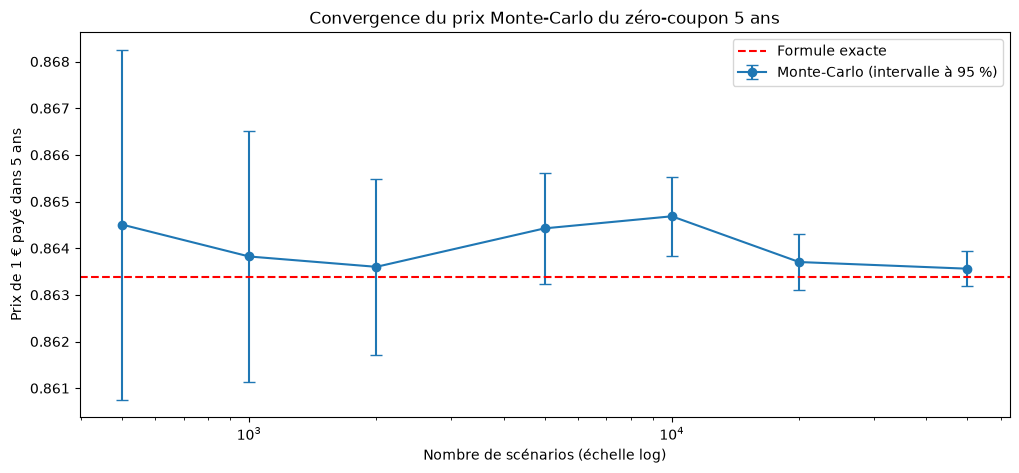

In [11]:
# Erreur Monte-Carlo : convergence du prix P(0,5) avec le nombre de scénarios
sizes = [500, 1000, 2000, 5000, 10000, 20000, 50000]
D_5 = discounts.loc[maturity]

mc_price = [D_5.iloc[:n].mean() for n in sizes]
half_width = [1.96*D_5.iloc[:n].std()/np.sqrt(n) for n in sizes]

fig, ax = plt.subplots(figsize=(12, 5))
ax.errorbar(sizes, mc_price, yerr=half_width, fmt="o-", capsize=4, label="Monte-Carlo (intervalle à 95 %)")
ax.axhline(zcb_price(maturity, r_0), color="red", ls="--", label="Formule exacte")
ax.set_xscale("log")
ax.set_title("Convergence du prix Monte-Carlo du zéro-coupon 5 ans")
ax.set_xlabel("Nombre de scénarios (échelle log)")
ax.set_ylabel("Prix de 1 € payé dans 5 ans")
ax.legend()
plt.show()

In [12]:
# Biais de discrétisation : même nombre de scénarios, pas de temps différents
for spy in [12, 52, 252]:
    sim = cir_short_rates(n_years=maturity, n_scenarios=n_scenarios, steps_per_year=spy, seed=seed)
    price_mc = discount_factors(sim, steps_per_year=spy).iloc[-1].mean()
    gap = (price_mc - zcb_price(maturity, r_0))*10000
    print(f"{spy:>3} pas par an : prix MC = {price_mc:.5f} | écart = {gap:+.1f} pb")

 12 pas par an : prix MC = 0.86389 | écart = +5.1 pb


 52 pas par an : prix MC = 0.86356 | écart = +1.8 pb


252 pas par an : prix MC = 0.86366 | écart = +2.7 pb


**Interprétation :** Avec un pas mensuel, l'écart atteint environ 5 pb : la somme $\sum r_{t_k}\Delta t$ approxime moins bien l'intégrale. Avec un pas hebdomadaire ou quotidien, l'écart tombe à 2 pb ce qui est **à l'intérieur de l'intervalle de confiance Monte-Carlo** (environ $\pm 1{,}96 \times 1{,}9 \approx \pm 3{,}7$ pb). Au-delà du pas hebdomadaire, réduire encore $\Delta t$ n'apporte donc plus de gain mesurable : c'est l'erreur Monte-Carlo qui domine. C'est pourquoi je retiendrai `steps_per_year = 52` pour la suite.


### La courbe des taux implicite du modèle

Avec la formule exacte, on obtient la courbe complète des prix et des taux zéro-coupon d'aujourd'hui.

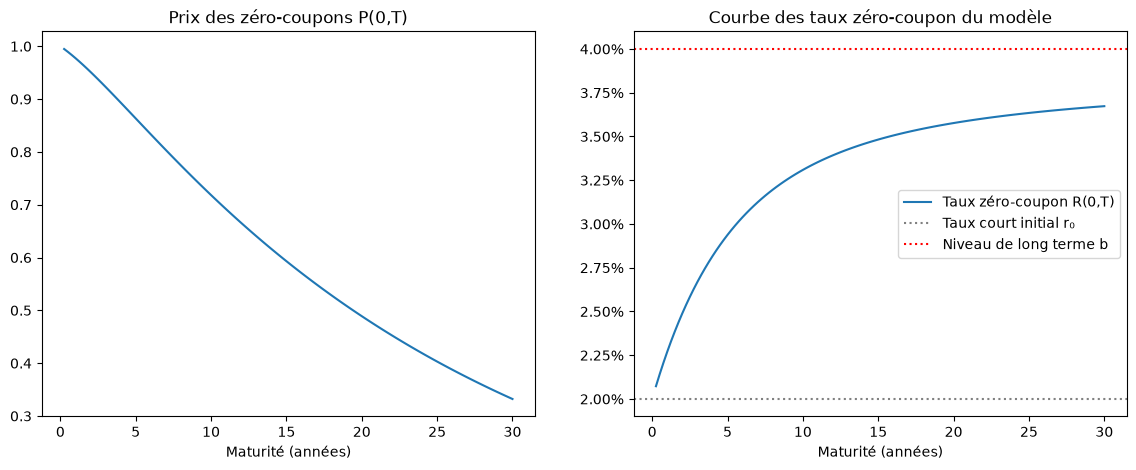

In [13]:
maturities = np.arange(0.25, 30.25, 0.25)
zc_prices = zcb_price(maturities, r_0)
zc_rates = -np.log(zc_prices)/maturities

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(maturities, zc_prices)
ax1.set_title("Prix des zéro-coupons P(0,T)")
ax1.set_xlabel("Maturité (années)")

ax2.plot(maturities, zc_rates, label="Taux zéro-coupon R(0,T)")
ax2.axhline(r_0, color="grey", ls=":", label="Taux court initial r₀")
ax2.axhline(b, color="red", ls=":", label="Niveau de long terme b")
ax2.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax2.set_title("Courbe des taux zéro-coupon du modèle")
ax2.set_xlabel("Maturité (années)")
ax2.legend()
plt.show()

**Interprétation :** La courbe est **croissante** car le taux court actuel (2 %) est inférieur à son niveau de long terme (4 %) : le marché « anticipe » sous $\mathbb{Q}$ une remontée des taux. Elle reste un peu sous 4 % aux longues maturités du fait de l'effet de **convexité** : l'incertitude sur les taux augmente légèrement la valeur des zéro-coupons.

**Limite toutefois** : un modèle à un facteur avec trois paramètres ne peut pas reproduire exactement n'importe quelle courbe de marché.

## 4. Zéro-coupons et taux forwards

Le **taux forward** $F(0,T_1,T_2)$ est le taux que l'on peut garantir **aujourd'hui** pour un placement entre deux dates futures $T_1$ et $T_2$. Il découle de l'**A0A**.

**Exemple.** Deux façons de placer de l'argent jusqu'en $T_2$ :
- placer directement jusqu'en $T_2$ ;
- placer jusqu'en $T_1$, puis replacer entre $T_1$ et $T_2$ au taux $F$ fixé dès aujourd'hui.

Les deux doivent rapporter la même chose, sinon on gagnerait sans risque en combinant les deux. D'où, avec $\delta = T_2 - T_1$ et un taux simple comme pour l'Euribor :

$$ 1 + \delta\,F(0,T_1,T_2) = \frac{P(0,T_1)}{P(0,T_2)} \qquad \Longrightarrow \qquad F(0,T_1,T_2) = \frac{1}{\delta}\left(\frac{P(0,T_1)}{P(0,T_2)} - 1\right) $$

Ces forwards représentent les taux variables « attendus » sous la mesure adaptée à chaque date de paiement. Ils seront donc le point de référence des swaps et des caps.

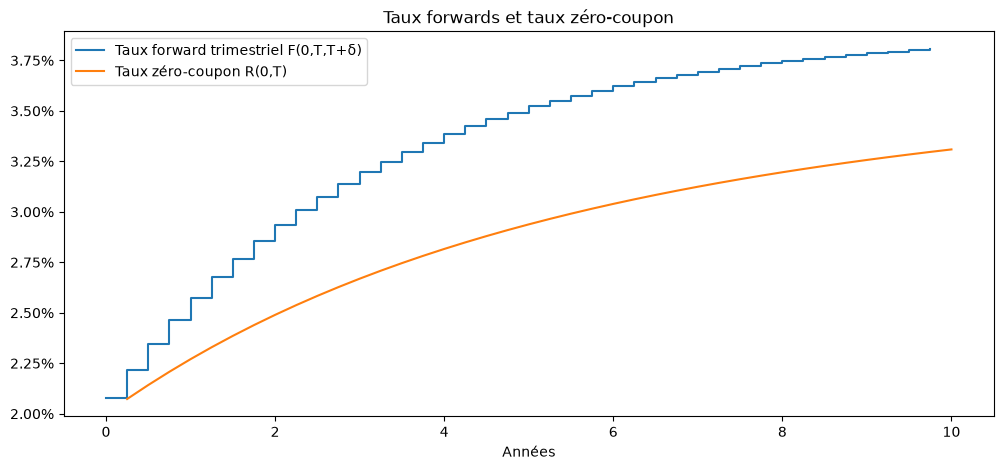

In [14]:
def forward_rate(T1, T2, r_0=r_0):
    """
    Taux forward simple entre T1 et T2, implicite dans la courbe CIR d'aujourd'hui
    """
    return (zcb_price(T1, r_0)/zcb_price(T2, r_0) - 1) / (T2 - T1)

fixing_dates = np.arange(0, 10, delta)
forwards = forward_rate(fixing_dates, fixing_dates + delta)

fig, ax = plt.subplots(figsize=(12, 5))
ax.step(fixing_dates, forwards, where="post", label="Taux forward trimestriel F(0,T,T+δ)")
ax.plot(maturities[maturities <= 10], zc_rates[maturities <= 10], label="Taux zéro-coupon R(0,T)")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.set_title("Taux forwards et taux zéro-coupon")
ax.set_xlabel("Années")
ax.legend()
plt.show()

**Interprétation :** Les forwards sont au-dessus des taux zéro-coupon : le taux zéro-coupon est une sorte de moyenne des forwards jusqu'à la maturité. Quand la courbe monte, le taux « marginal » (le forward) dépasse la moyenne accumulée.

## 5. Application à un dérivé : le swap de taux (IRS)

### 5.1 Explication du produit

Une entreprise emprunte 1 M€ sur 5 ans au taux variable trimestriel $L$ et craint une hausse des taux. Elle conclut un **swap payeur** :
- elle **paie un taux fixe** $K$ ;
- elle **reçoit le taux variable** $L$, qui compense les intérêts de son emprunt.

Au total, elle paie un taux fixe : son coût est stabilisé. À chaque date, le flux net reçu vaut $N\,\delta\,(L_i - K)$.

### 5.2 Pricing

Le swap ne contient **aucune option** : il se valorise uniquement avec les zéro-coupons d'aujourd'hui, sans simulation.

- **Jambe fixe :** une suite de flux connus $N K \delta$, chacun actualisé :
$$ V_{\text{fixe}} = N\,K \sum_{i=1}^{n} \delta\,P(0,T_i) $$
La somme $\sum \delta P(0,T_i)$ s'appelle l'**annuité** : la valeur d'un flux de 1 € par an, versé trimestriellement.

- **Jambe variable :** recevoir les intérêts variables plus le nominal à la fin équivaut à détenir un prêt à taux variable, qui vaut toujours le nominal au départ. Sans le remboursement final :
$$ V_{\text{variable}} = N\left(1 - P(0,T_n)\right) $$

Valeur du swap payeur et **taux de swap « par »**, celui qui donne une valeur nulle à la signature :

$$ V_{\text{swap}} = N\left(1 - P(0,T_n)\right) - N K \sum_{i=1}^{n} \delta\,P(0,T_i) \qquad\qquad K_{\text{par}} = \frac{1 - P(0,T_n)}{\sum_{i=1}^{n}\delta\,P(0,T_i)} $$

**Exemple :** si l'annuité vaut 4,6 et $P(0,5) = 0{,}865$, alors $K_{\text{par}} = 0{,}135/4{,}6 \approx 2{,}93\,\%$.

In [15]:
def swap_value(K, maturity=maturity, delta=delta, notional=N, r_0=r_0):
    """
    Valeur d'un swap payeur fixe K / receveur variable, démarrant aujourd'hui
    """
    payment_dates = np.arange(delta, maturity + delta/2, delta)
    P = zcb_price(payment_dates, r_0)
    annuity = (delta*P).sum()
    floating_leg = notional*(1 - P[-1])
    fixed_leg = notional*K*annuity
    return floating_leg - fixed_leg


def par_swap_rate(maturity=maturity, delta=delta, r_0=r_0):
    """
    Taux fixe qui annule la valeur du swap à la signature
    """
    payment_dates = np.arange(delta, maturity + delta/2, delta)
    P = zcb_price(payment_dates, r_0)
    return (1 - P[-1]) / (delta*P).sum()


K_par = par_swap_rate()
print(f"Taux de swap par 5 ans : {K_par:.3%}")
print(f"Valeur d'un swap conclu au taux par : {swap_value(K_par):.2f} €")
print(f"Valeur d'un swap payeur à 2,50 %     : {swap_value(0.025):,.0f} €")

Taux de swap par 5 ans : 2.931%
Valeur d'un swap conclu au taux par : 0.00 €
Valeur d'un swap payeur à 2,50 %     : 20,094 €


**Interprétation :** Un swap payeur à 2,50 % a une **valeur positive** : l'entreprise paie un taux fixe inférieur au taux de marché, ce qui est avantageux pour elle.

### 5.3 Courbe des swaps et sensibilité aux taux

Je présenterai ici deux graphiques : le taux de swap selon la maturité, puis la valeur d'un swap 5 ans conclu au taux par lorsque les taux se déplacent. Dans un modèle à un facteur, déplacer $r_0$ déplace toute la courbe soit davantage sur les maturités courtes que sur les longues.

On mesure la sensibilité par la **DV01** ( variation de valeur pour une hausse de 1 pb du taux court calculée par différence finie.)

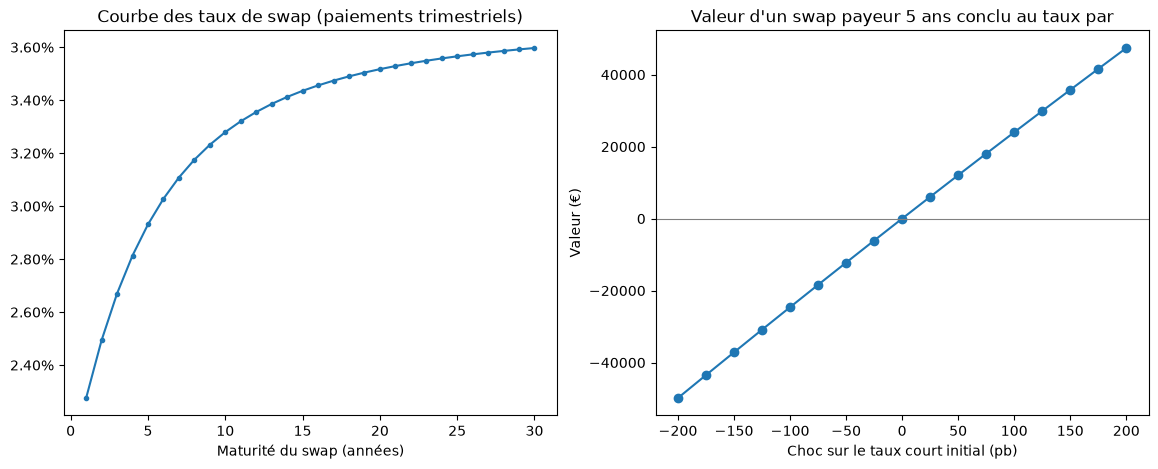

DV01 du swap payeur (choc de +1 pb sur r_0) : 242.99 €


In [16]:
swap_maturities = np.arange(1, 31)
swap_curve = [par_swap_rate(maturity=m) for m in swap_maturities]

shocks = np.arange(-0.02, 0.0201, 0.0025)     # de -200 pb à +200 pb sur r_0
values = [swap_value(K_par, r_0=max(r_0 + s, 0)) for s in shocks]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(swap_maturities, swap_curve, marker="o", ms=3)
ax1.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax1.set_title("Courbe des taux de swap (paiements trimestriels)")
ax1.set_xlabel("Maturité du swap (années)")

ax2.plot(shocks*10000, values, marker="o")
ax2.axhline(0, color="grey", lw=0.8)
ax2.set_title("Valeur d'un swap payeur 5 ans conclu au taux par")
ax2.set_xlabel("Choc sur le taux court initial (pb)")
ax2.set_ylabel("Valeur (€)")
plt.show()

dv01 = swap_value(K_par, r_0=r_0 + 0.0001) - swap_value(K_par)
print(f"DV01 du swap payeur (choc de +1 pb sur r_0) : {dv01:,.2f} €")

**Interprétation :** Le swap payeur **gagne de la valeur quand les taux montent** : il paie un taux fixe désormais inférieur au marché. C'est exactement la protection recherchée par l'emprunteur. La relation est presque linéaire : un swap est un produit **sans optionalité**. Il protège contre la hausse, mais fait perdre le bénéfice d'une baisse.


## 6. Ajout de l'optionnalité : caplet et cap

### 6.1 Explication du produit

Un **caplet** est une option d'achat sur le taux variable. À la date de fixing $T$, on observe le taux $L(T, T+\delta)$ ; en $T+\delta$, l'acheteur reçoit :

$$ \text{Payoff}_{T+\delta} = N\,\delta\,\max\left(L(T,T+\delta) - K,\ 0\right) $$

**Exemple :** nominal 1 M€, trimestre ($\delta = 0{,}25$), strike $K = 3\,\%$. Si le taux est fixé à 5 % : $1\,000\,000 \times 0{,}25 \times 2\,\% = 5\,000$ €. Si le taux est fixé à 2 % : rien.

Le **cap** est une suite de caplets sur toutes les périodes du prêt. Pour un emprunteur à taux variable, il plafonne le taux payé à $K$, tout en conservant le bénéfice d'une baisse des taux. Contrairement au swap, cette protection a donc un **coût initial** : la prime.

### 6.2 Pricing par Monte-Carlo

Trois étapes dans chaque scénario :

1. **Lire le taux court** $r_T$ à la date de fixing.
2. **Déduire le taux variable fixé.** Le taux $L(T,T+\delta)$ n'est pas le taux court $r_T$ : c'est le taux simple d'un placement de durée $\delta$, déduit du prix du zéro-coupon en $T$, donné par la formule exacte :
$$ L(T,T+\delta) = \frac{1}{\delta}\left(\frac{1}{P(T,T+\delta)} - 1\right) $$
3. **Actualiser.** Le flux est connu en $T$ mais payé en $T+\delta$ : sa valeur en $T$ est le flux multiplié par $P(T,T+\delta)$. On actualise ensuite de $T$ à 0 avec $D(0,T)$ :
$$ \text{Caplet}_0 = \mathbb{E}^{\mathbb{Q}}\left[ D(0,T)\;P(T,T+\delta)\; N\,\delta\,\max(L - K, 0) \right] \qquad\qquad \text{Cap}_0 = \sum_i \text{Caplet}_0(T_i) $$


In [17]:
def caplet_price(T, K, rates, discounts, kind="cap", delta=delta, notional=N, sigma=sigma):
    """
    Prix Monte-Carlo d'un caplet (ou d'un floorlet) fixé en T et payé en T + delta
    """
    step = int(round(T*steps_per_year))
    r_T = rates.iloc[step]                          # taux court en T, un par scénario
    P_T = zcb_price(delta, r_T, sigma=sigma)        # prix en T du zéro-coupon qui paie 1 en T + delta
    L = (1/P_T - 1)/delta                           # taux variable fixé en T

    if kind == "cap":
        payoff = np.maximum(L - K, 0)
    else:
        payoff = np.maximum(K - L, 0)

    value_at_T = notional*delta*payoff*P_T          # flux payé en T + delta, ramené en T
    return (discounts.iloc[step]*value_at_T).mean()


def cap_price(K, rates, discounts, kind="cap", maturity=maturity, delta=delta, sigma=sigma):
    """
    Prix de chaque caplet (ou floorlet) d'un cap (ou floor) : le prix total est la somme
    """
    fixing_dates = np.arange(0, maturity, delta)
    prices = [caplet_price(T, K, rates, discounts, kind=kind, delta=delta, sigma=sigma) for T in fixing_dates]
    return pd.Series(prices, index=fixing_dates)

L'argument `sigma` est transmis jusqu'à `zcb_price` : quand on change la volatilité pour une analyse de sensibilité, la simulation **et** la formule du zéro-coupon doivent utiliser la même valeur.

### 6.3 Cap 5 ans de strike 4 %

Prix du cap 5 ans, strike 4% : 10,683 €
  soit 1.07% du nominal, payé à la signature
  ou   0.23% par an, si la prime est étalée sur la durée du prêt


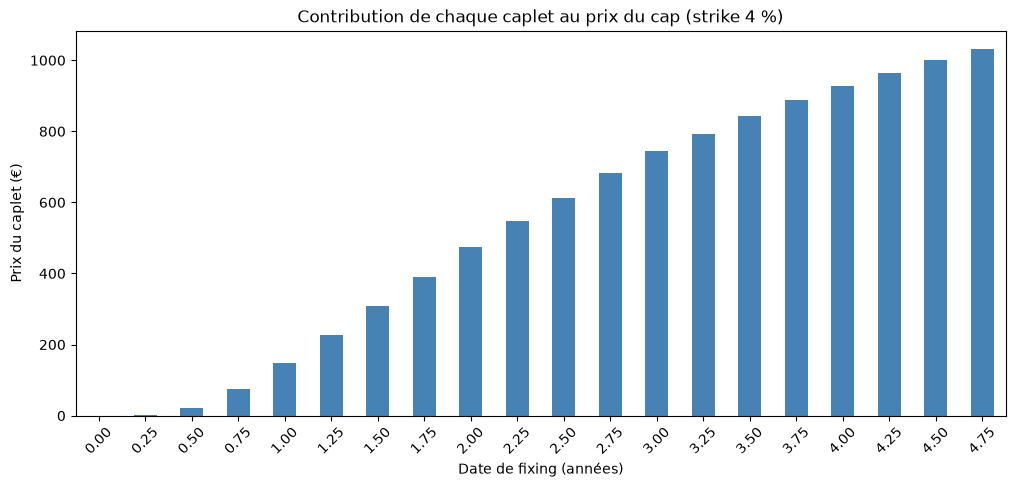

In [18]:
K_cap = 0.04
caplets = cap_price(K_cap, rates, discounts)

payment_dates = np.arange(delta, maturity + delta/2, delta)
annuity = (delta*zcb_price(payment_dates, r_0)).sum()
cap_premium = caplets.sum()

print(f"Prix du cap 5 ans, strike {K_cap:.0%} : {cap_premium:,.0f} €")
print(f"  soit {cap_premium/N:.2%} du nominal, payé à la signature")
print(f"  ou   {cap_premium/(N*annuity):.2%} par an, si la prime est étalée sur la durée du prêt")

ax = caplets.plot.bar(figsize=(12, 5), color="steelblue")
ax.set_xticklabels([f"{T:.2f}" for T in caplets.index], rotation=45)
ax.set_title("Contribution de chaque caplet au prix du cap (strike 4 %)")
ax.set_xlabel("Date de fixing (années)")
ax.set_ylabel("Prix du caplet (€)")
plt.show()

**Interprétation :** Les premiers caplets valent presque rien : le taux variable actuel (≈ 2 %) est loin du strike de 4 %, et il a peu de temps pour le franchir. Les caplets lointains valent davantage pour deux raisons : les **forwards sont plus élevés** (courbe croissante) et le taux a **plus de temps pour fluctuer**, donc plus de chances de dépasser le strike.

Étaler la prime en taux annuel, en la divisant par l'annuité, permet de comparer directement son coût au taux de l'emprunt.

### 6.4 Sensibilités du cap : strike et volatilité

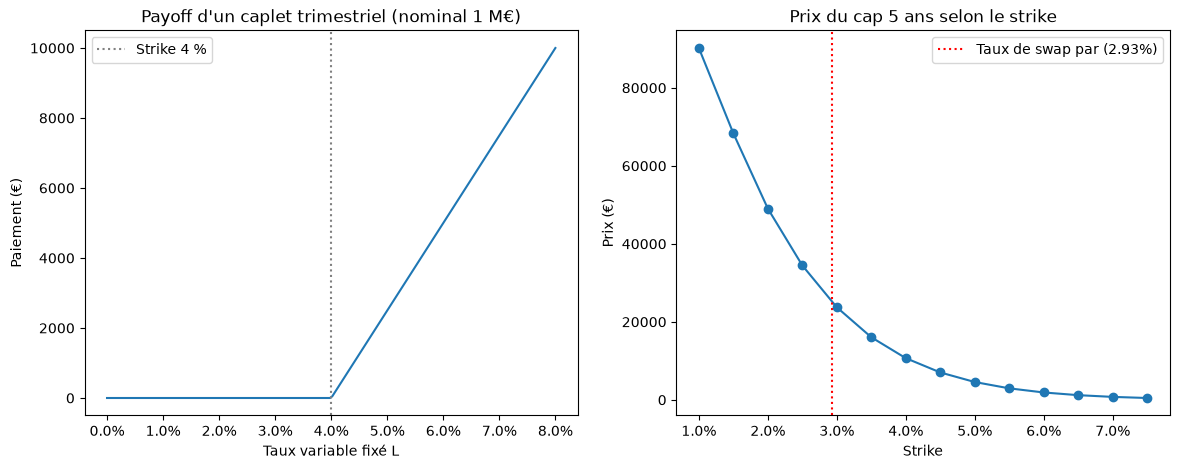

In [19]:
# Payoff d'un caplet selon le taux fixé
L_grid = np.linspace(0, 0.08, 200)
caplet_payoff = N*delta*np.maximum(L_grid - K_cap, 0)

# Prix du cap selon le strike
strikes = np.arange(0.01, 0.0751, 0.005)
cap_by_strike = [cap_price(K, rates, discounts).sum() for K in strikes]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(L_grid, caplet_payoff)
ax1.axvline(K_cap, color="grey", ls=":", label="Strike 4 %")
ax1.xaxis.set_major_formatter(PercentFormatter(xmax=1))
ax1.set_title("Payoff d'un caplet trimestriel (nominal 1 M€)")
ax1.set_xlabel("Taux variable fixé L")
ax1.set_ylabel("Paiement (€)")
ax1.legend()

ax2.plot(strikes, cap_by_strike, marker="o")
ax2.axvline(K_par, color="red", ls=":", label=f"Taux de swap par ({K_par:.2%})")
ax2.xaxis.set_major_formatter(PercentFormatter(xmax=1))
ax2.set_title("Prix du cap 5 ans selon le strike")
ax2.set_xlabel("Strike")
ax2.set_ylabel("Prix (€)")
ax2.legend()
plt.show()

Pour la sensibilité à la volatilité, je relance la simulation avec la **même seed** pour chaque valeur de $\sigma$ : les chocs aléatoires sont identiques donc seule la volatilité change. Cette technique des **nombres aléatoires communs** évite que le bruit Monte-Carlo masque l'effet étudié.

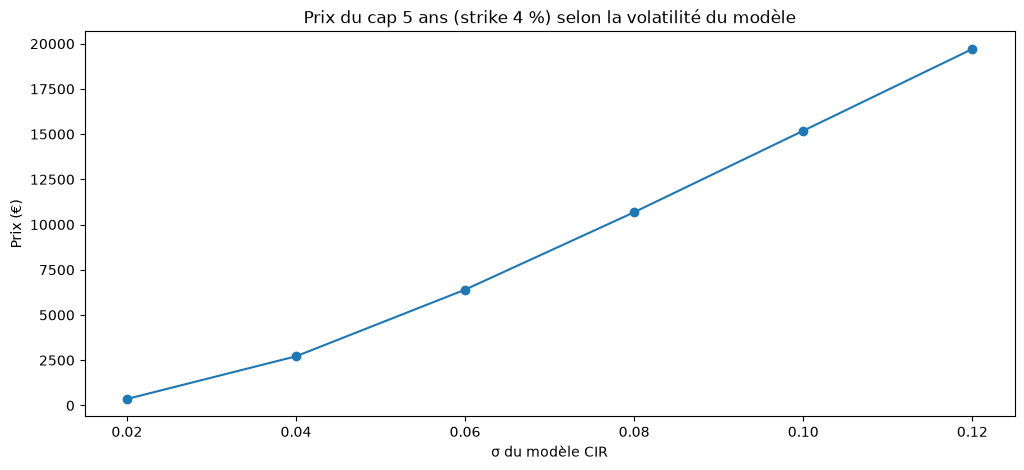

In [20]:
sigmas = [0.02, 0.04, 0.06, 0.08, 0.10, 0.12]
cap_by_sigma = []

for s in sigmas:
    sim = cir_short_rates(n_years=maturity, n_scenarios=n_scenarios, sigma=s, seed=seed)
    cap_by_sigma.append(cap_price(K_cap, sim, discount_factors(sim), sigma=s).sum())

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(sigmas, cap_by_sigma, marker="o")
ax.set_title("Prix du cap 5 ans (strike 4 %) selon la volatilité du modèle")
ax.set_xlabel("σ du modèle CIR")
ax.set_ylabel("Prix (€)")
plt.show()

**Interprétation :**
- **Strike :** plus le strike est bas, plus la protection est généreuse, donc chère. Le prix décroît sans jamais devenir négatif : une option ne peut pas avoir de valeur négative.
- **Volatilité :** le prix augmente avec $\sigma$. C'est l'asymétrie de l'option : davantage de volatilité augmente les gains possibles au-dessus du strike, alors que la perte de l'acheteur reste limitée à sa prime.

C'est la différence fondamentale avec le swap, dont la valeur ne dépend que de la courbe, pas de la volatilité.

## 7. Ajout du floor et parité cap–floor

Un **floor** est le symétrique du cap : une suite de **floorlets** qui paient $N\,\delta\,\max(K - L, 0)$. Il protège le **prêteur** contre la baisse des taux.

Sur chaque période, acheter un caplet et vendre un floorlet de même strike donne :

$$ \max(L - K, 0) - \max(K - L, 0) = L - K $$

C'est exactement le flux d'un swap payeur. D'où la **parité cap–floor** :

$$ \text{Cap}(K) - \text{Floor}(K) = \text{Swap payeur}(K) $$

Cette relation ne dépend d'aucune hypothèse de modèle : c'est un **test indépendant** de mon implémentation. Le cap et le floor sont calculés par Monte-Carlo, le swap par la formule fermée ; si le code est correct, les deux côtés doivent donc concorder.

Conséquence : au strike égal au taux de swap par, le swap vaut 0, donc **cap et floor ont le même prix**. C'est la définition du strike « à la monnaie ».

In [21]:
parity = pd.DataFrame(index=[0.02, 0.025, round(K_par, 4), 0.035, 0.04])

for K in parity.index:
    parity.loc[K, "Cap (MC)"] = cap_price(K, rates, discounts).sum()
    parity.loc[K, "Floor (MC)"] = cap_price(K, rates, discounts, kind="floor").sum()
    parity.loc[K, "Swap payeur (formule)"] = swap_value(K)

parity["Cap - Floor"] = parity["Cap (MC)"] - parity["Floor (MC)"]
parity["Écart (pb du nominal)"] = (parity["Cap - Floor"] - parity["Swap payeur (formule)"]) / N * 10000
parity.index = [f"{K:.2%}" for K in parity.index]
parity.index.name = "Strike"
parity.round(1)

,Cap (MC),Floor (MC),Swap payeur (formule),Cap - Floor,Écart (pb du nominal)
Strike,,,,,
2.00%,49045.6,5693.1,43398.3,43352.5,-0.5
2.50%,34456.4,14411.4,20093.7,20045.0,-0.5
2.93%,25032.0,25031.4,51.8,0.5,-0.5
3.50%,16046.7,42616.7,-26515.4,-26570.0,-0.5
4.00%,10683.2,60560.7,-49819.9,-49877.4,-0.6


**Interprétation :** L'écart est inférieur à 1 pb du nominal pour tous les strikes : le Monte-Carlo des options et la formule exacte du swap sont cohérents. L'écart résiduel provient des erreurs Monte-Carlo et de discrétisation identifiées plus tôt.

Ce type de vérification est essentiel : un pricer qui ne respecte pas une relation d'arbitrage ne pourrait pas être utilisé.

## 8. Application à un produit structuré : le collar de taux

### 8.1 Besoin du client

Reprenons l'entreprise endettée à taux variable sur 5 ans. Elle veut être protégée au-delà de 4 %, mais **ne souhaite pas payer la prime du cap**, environ 1 % du nominal.

Solution du desk : **acheter le cap à 4 % et vendre un floor**. La prime reçue sur le floor finance celle du cap. En contrepartie, l'entreprise renonce à la baisse des taux sous le strike du floor $K_f$.

Le taux effectivement payé devient, à chaque période :

$$ \text{Taux payé} = L + \underbrace{\max(K_f - L, 0)}_{\text{floor vendu}} - \underbrace{\max(L - K_c, 0)}_{\text{cap acheté}} = \min\left(\max(L,\ K_f),\ K_c\right) $$

Le taux reste dans un **tunnel** $[K_f,\ K_c]$.

### 8.2 Identification du collar à coût nul

On cherche le strike $K_f$ tel que le floor rapporte exactement la prime du cap :

$$ \text{Floor}(K_f) = \text{Cap}(K_c) $$

Il n'y a pas de formule directe : on résout numériquement avec `brentq` qui cherche le zéro d'une fonction dans un intervalle où elle change de signe. Ici, entre 0,1 % (floor quasi nul, inférieur à la prime) et 4 % (floor plus cher que le cap).

In [22]:
K_cap = 0.04
cap_premium = cap_price(K_cap, rates, discounts).sum()

def premium_gap(K_floor):
    return cap_price(K_floor, rates, discounts, kind="floor").sum() - cap_premium

K_floor = brentq(premium_gap, 0.001, K_cap)

print(f"Prime du cap à {K_cap:.2%}          : {cap_premium:,.0f} €")
print(f"Strike du floor à coût nul : {K_floor:.2%}")
print(f"Prime du floor vendu       : {cap_price(K_floor, rates, discounts, kind='floor').sum():,.0f} €")

Prime du cap à 4.00%          : 10,683 €
Strike du floor à coût nul : 2.32%
Prime du floor vendu       : 10,683 €


### 8.3 Comparaison de trois stratégies pour l'emprunteur

Le premier graphique compare le taux payé selon le taux variable observé :
- **sans couverture** : l'entreprise paie $L$ ;
- **avec cap seul** : elle paie $\min(L, K_c)$ plus la prime étalée sur la durée ;
- **avec collar à coût nul** : elle paie $\min(\max(L, K_f), K_c)$.

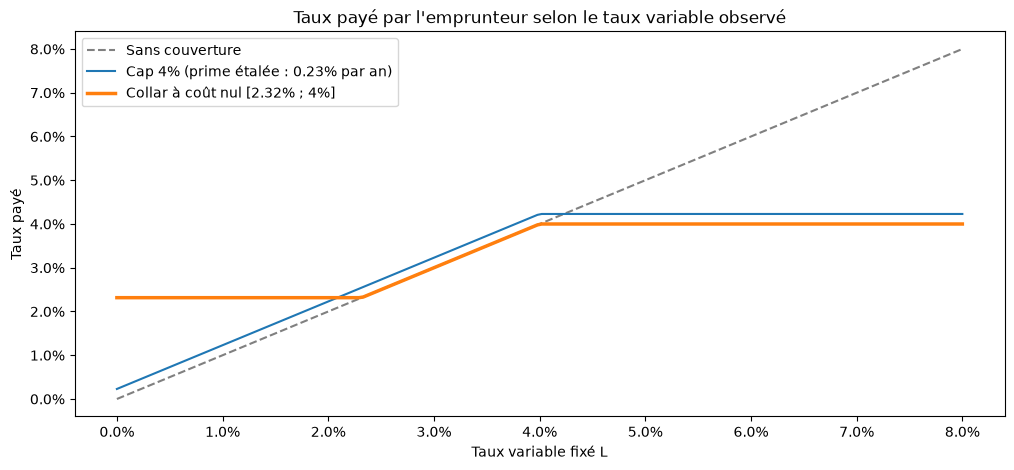

In [23]:
cap_running_cost = cap_premium/(N*annuity)     # prime du cap exprimée en taux annuel

no_hedge = L_grid
with_cap = np.minimum(L_grid, K_cap) + cap_running_cost
with_collar = np.clip(L_grid, K_floor, K_cap)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(L_grid, no_hedge, label="Sans couverture", color="grey", ls="--")
ax.plot(L_grid, with_cap, label=f"Cap {K_cap:.0%} (prime étalée : {cap_running_cost:.2%} par an)")
ax.plot(L_grid, with_collar, label=f"Collar à coût nul [{K_floor:.2%} ; {K_cap:.0%}]", lw=2.5)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.set_title("Taux payé par l'emprunteur selon le taux variable observé")
ax.set_xlabel("Taux variable fixé L")
ax.set_ylabel("Taux payé")
ax.legend()
plt.show()

Le second graphique utilise les 50 000 scénarios simulés : pour chacun, je calcule le **taux moyen payé sur les 5 ans** (moyenne simple des 20 fixings trimestriels), sans couverture puis avec le collar.

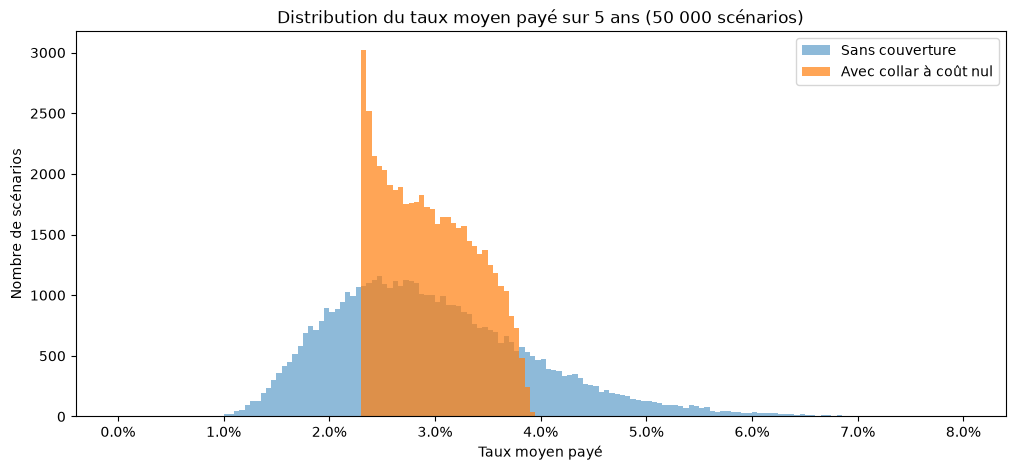

,Sans couverture,Collar
mean,2.98%,2.95%
std,0.97%,0.43%
5%,1.65%,2.34%
95%,4.77%,3.69%
max,9.43%,3.92%


In [24]:
fixing_dates = np.arange(0, maturity, delta)
fixings = pd.DataFrame(index=fixing_dates, columns=rates.columns, dtype=float)

for T in fixing_dates:
    r_T = rates.iloc[int(round(T*steps_per_year))]
    fixings.loc[T] = (1/zcb_price(delta, r_T) - 1)/delta

avg_no_hedge = fixings.mean()
avg_collar = fixings.clip(K_floor, K_cap).mean()

fig, ax = plt.subplots(figsize=(12, 5))
bins = np.linspace(0, 0.08, 161)    # mêmes classes pour les deux histogrammes
ax.hist(avg_no_hedge, bins=bins, alpha=0.5, label="Sans couverture")
ax.hist(avg_collar, bins=bins, alpha=0.7, label="Avec collar à coût nul")
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.set_title("Distribution du taux moyen payé sur 5 ans (50 000 scénarios)")
ax.set_xlabel("Taux moyen payé")
ax.set_ylabel("Nombre de scénarios")
ax.legend()
plt.show()

summary = pd.DataFrame({"Sans couverture": avg_no_hedge, "Collar": avg_collar}).describe(percentiles=[0.05, 0.95])
summary.loc[["mean", "std", "5%", "95%", "max"]].map(lambda x: f"{x:.2%}")

**Interprétation :**
- Le collar **resserre fortement la distribution** du coût de la dette : les scénarios de forte hausse sont plafonnés, et le budget de l'entreprise devient prévisible.
- Il n'est pas gratuit pour autant car « coût nul » signifie **aucune prime à la signature**. Le prix de la protection est payé dans les scénarios de baisse des taux, où l'entreprise paie $K_f$ au lieu d'un taux plus faible.
- Le choix entre swap, cap et collar est un **arbitrage entre certitude, coût initial et participation à la baisse** : c'est précisément le dialogue entre un structureur et son client.

| Stratégie | Prime initiale | Protection contre la hausse | Bénéfice d'une baisse |
|---|---|---|---|
| Swap payeur | Aucune | Totale (taux fixe) | Aucun |
| Cap | Payée | Au-delà de $K_c$ | Total |
| Collar à coût nul | Aucune | Au-delà de $K_c$ | Jusqu'à $K_f$ seulement |

## 9. Limites et bilan

### Démarche de réalisation
À partir du modèle CIR, un **pricer Monte-Carlo sous probabilité risque-neutre** : zéro-coupons, forwards, swaps, caps, floors et collars avec des analyses de sensibilité au taux au strike ainsi qu'à la volatilité.

### Démarche de validation
1. **Moyenne simulée** du taux court comparée à son espérance théorique.
2. **Prix Monte-Carlo du zéro-coupon** comparé à la formule fermée du CIR en séparant erreur Monte-Carlo et biais de discrétisation.
3. **Parité cap–floor** => une relation d'arbitrage indépendante du modèle vérifiée à moins de 1 pb du nominal.

### Limites du projet
- **Paramètres non calibrés.** Ils sont illustratifs. Un CIR à un facteur ne peut pas reproduire exactement une courbe de marché ni un smile de volatilité de caps. En pratique, on utiliserait une extension qui colle à la courbe initiale (CIR++ ou Hull-White), calibrée sur les prix de caps et de swaptions.
- **Un seul facteur.** Tous les taux sont pilotés par $r_t$ : les taux courts et longs sont parfaitement corrélés, ce qui exclut les déformations de pente indépendantes.
- **Une seule courbe.** Le même taux sert à projeter l'Euribor et à actualiser. Depuis 2008, les marchés séparent la courbe de projection et la courbe d'actualisation (€STR).
- **Conventions simplifiées.** Base de calcul des jours, calendrier et premier caplet ont été simplifiés.
- **Schéma numérique.** Le schéma d'Euler avec réflexion `abs(...)` est une approximation ; il est suffisant ici car la condition de Feller est respectée.

### Suite du projet
L'**extension FX** : deux courbes de taux CIR, domestique et étrangère, pour valoriser des forwards de change, puis des options de change à taux stochastiques.